# Investigating Glacial and Interglacial Cycles with Python
**GEOG 202 Honors | Guided in-class investigation (~75–90 minutes)**

**Big question:** What is the dominant rhythm?

**Learning goals:** 
1) read and plot climate data; 
2) connect eccentricity, obliquity, and precession to seasonal insolation;
3) interpret CO₂ and benthic δ¹⁸O records; 
4) compare ~41-kyr and ~100-kyr variability.

**Instructions:** Run code cells in order with **Shift + Enter**. Code is provided; your job is to experiment and explain. Write answers in the markdown response cells or on the print out. 

**ka** means thousands of years before present.

___
## Before you begin: data files
This notebook uses the **original datasets referenced by the two course notebooks**.

- `INSOLN.LA2004.BTL.100.csv` — orbital parameters
- `j_65north.csv` — 65°N insolation
- `antarctica2015co2composite.txt` — Antarctic CO₂ composite
- `LR04stack.csv` — LR04 benthic oxygen-isotope stack

**Tip:** If a cell reports `FileNotFoundError`, check the `data` folder before continuing.
___

In [21]:
# # Retrieve data from Git Hub if using Colab. Uncomment the following lines to clone the repository and change the working directory.
# !git clone https://github.com/marositesUSC/glacial-cycles.git
# %cd glacial-cycles


In [1]:
# We are going to use several libraries to help us in our analysis.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.interpolate import interp1d
from IPython.display import display, Markdown

# Lets make sure we have all the files we need.
files = ["INSOLN.LA2004.BTL.100.csv", "j_65north.csv", "antarctica2015co2composite.txt", "LR04stack.csv"]
for name in files:
    print(("FOUND  " if (Path("data") / name).exists() else "MISSING"), name)
print("\nAll datasets available:", all((Path("data") / f).exists() for f in files))

FOUND   INSOLN.LA2004.BTL.100.csv
FOUND   j_65north.csv
FOUND   antarctica2015co2composite.txt
FOUND   LR04stack.csv

All datasets available: True


## Part 1 — What is a cycle? (~10 minutes)
We use periods and frequencies to describe signals and how frequently events occur. 

Frequencies and periods describe how a repeating signal behaves across time and cycles:

Core Definitions
- Period (T): The duration of time (in seconds) it takes for a signal to complete one full, repeating cycle.
- Frequency (f): The number of complete cycles a signal finishes in one second, measured in Hertz (Hz). (or thousands of years, kyr, in climate science)
- The Reciprocal Relationship: Frequency and period are inverses of each other:  
            $f = \frac{1}{T} \quad \text{and} \quad T = \frac{1}{f}$  

A short period means a fast, high-frequency signal; a long period means a slow, low-frequency signal.

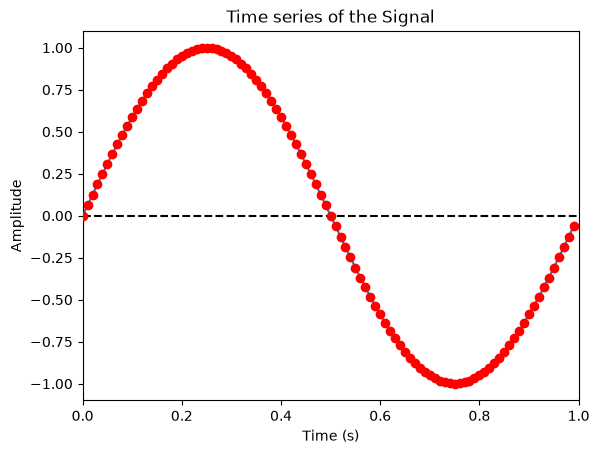

In [2]:
#Create time series of sine wave
target_freq= 1  #Frequency of signal generated. # cycles per second
fs = 100  # Sampling frequency in Hz # times per second
t = np.linspace(0, 1, fs, endpoint=False)  #Time series
sig = np.sin(2 * np.pi * target_freq * t) # y = sin(x)?

#Plot time series of Sine wave
plt.plot(t, sig)

plt.scatter(t, sig, color='red', zorder=10)
plt.axhline(0, color='black', linestyle='--', zorder=0)
plt.xlim(0,1)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Time series of the Signal')
plt.show()

A **period** is the time required for one complete repetition. A longer period means fewer cycles over a fixed time span. We often use periods to discuss climate cycles because they happen over very large time spans. 

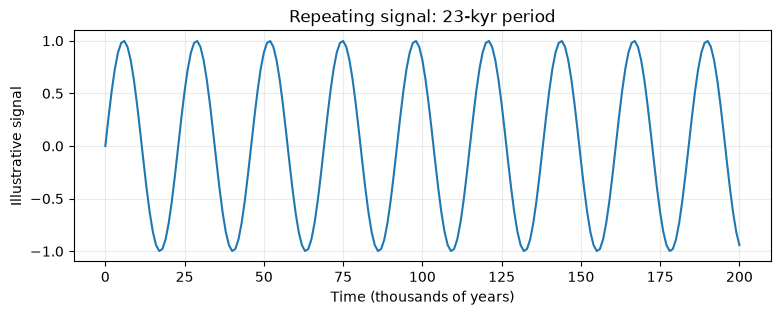

In [3]:
time_ka = np.arange(0, 201)
period_ka = 23  # TRY changing this to 23, 41, or 100
wave = np.sin(2 * np.pi * time_ka / period_ka)
plt.figure(figsize=(9, 3))
plt.plot(time_ka, wave)
plt.xlabel("Time (thousands of years)")
plt.ylabel("Illustrative signal")
plt.title(f"Repeating signal: {period_ka}-kyr period")
plt.grid(alpha=.25)
plt.show()

<font color='red'>**Question 1:**</font> Run the plot with periods of 23, 41, and 100 kyr. Which completes the most cycles over 200 kyr?

**Your answer:** ...

Most time series is the result of combined signals. Below we will add a signal that occurs every 41,000 years with a signal that occurs every 100,000 years

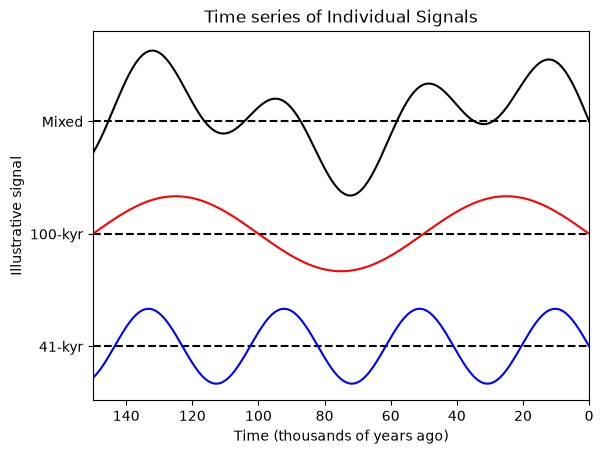

In [4]:
time_ka = np.arange(0, 501)

signal_41kyr = np.sin(2 * np.pi * time_ka / 41)
signal_100kyr = np.sin(2 * np.pi * time_ka / 100)

mixed = signal_41kyr + signal_100kyr
freq, power = signal.periodogram(mixed, fs=1, detrend="linear")
mask = freq > 0

plt.plot(time_ka, mixed, color='black', label='Mixed signal')
plt.plot(time_ka, signal_100kyr - 3, color='red', label='100-kyr signal')
plt.plot(time_ka, signal_41kyr - 6, color='blue', label='41-kyr signal'   )

plt.yticks(
    ticks=[-6, -3, 0], labels=["41-kyr", "100-kyr", "Mixed"], fontsize=10
)

plt.axhline(0, color='black', linestyle='--', zorder=0)
plt.axhline(-3, color='black', linestyle='--', zorder=0)
plt.axhline(-6, color='black', linestyle='--', zorder=0)


plt.title("Time series of Individual Signals")
plt.xlabel("Time (thousands of years ago)")
plt.ylabel("Illustrative signal")
plt.xlim(150,0)

plt.show()

### A simple introduction to spectral analysis
A **periodogram** shows how strongly different repeating timescales contribute to a signal. The code below uses a synthetic example, not climate observations.

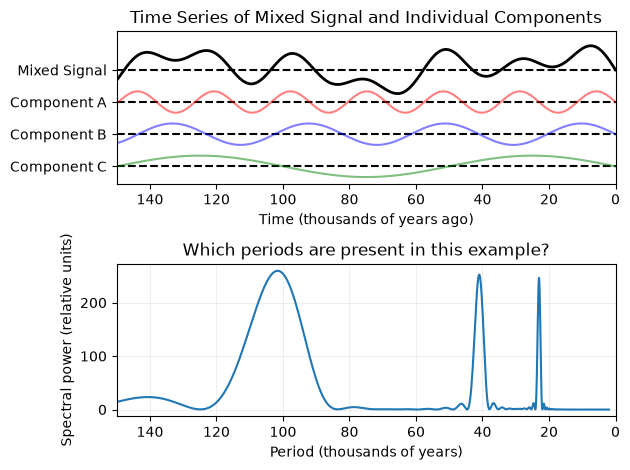

In [5]:
time_ka = np.arange(0, 501)
signal_23kyr = np.sin(2 * np.pi * time_ka / 23)
signal_41kyr = np.sin(2 * np.pi * time_ka / 41)
signal_100kyr = np.sin(2 * np.pi * time_ka / 100)

mixed = signal_23kyr + signal_41kyr + signal_100kyr
freq, power = signal.periodogram(mixed, fs=1, detrend=False, nfft=16384)
mask = freq > 0

plt.subplot(2,1,1)  

plt.plot(time_ka, mixed, color='black', label='Mixed signal', linewidth=2)
plt.plot(time_ka, signal_23kyr - 3, color='red', label='Component A',alpha=0.5)
plt.plot(time_ka, signal_41kyr - 6, color='blue', label='Component B', alpha=0.5)
plt.plot(time_ka, signal_100kyr - 9, color='green', label='Component C', alpha=0.5)

plt.yticks(
    ticks=[-9, -6, -3, 0], labels=["Component C", "Component B", "Component A", "Mixed Signal"], fontsize=10
)
plt.xlim(150,0)
plt.axhline(0, color='black', linestyle='--', zorder=0)
plt.axhline(-3, color='black', linestyle='--', zorder=0)
plt.axhline(-6, color='black', linestyle='--', zorder=0)
plt.axhline(-9, color='black', linestyle='--', zorder=0)
plt.title("Time Series of Mixed Signal and Individual Components" )
plt.xlabel("Time (thousands of years ago)")


plt.subplot(2,1,2)
plt.plot(1/freq[mask], power[mask])
plt.xlim(150, 0)
plt.xlabel("Period (thousands of years)")
plt.ylabel("Spectral power (relative units)")
plt.title("Which periods are present in this example?")
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

<font color='red'>**Question 2:**</font> Which periods are present in this example?

**Your answer:** ...

**Discussion:** Why might a climate record have more than one important period? 

Spectral peaks indicate recurring variability; by themselves they do **not** prove its cause.

## Part 2 — Milankovitch cycles and insolation (~15 minutes)

Our lives literally revolve around cycles: series of events that are repeated regularly in the same order. There are hundreds of different types of cycles in our world and in the universe. Some are natural, such as the change of the seasons, annual animal migrations or the circadian rhythms that govern our sleep patterns. Others are human-produced, like growing and harvesting crops, musical rhythms or economic cycles.

Cycles also play key roles in Earth’s short-term weather and long-term climate. A century ago, Serbian scientist Milutin Milankovitch hypothesized the long-term, collective effects of changes in Earth’s position relative to the Sun are a strong driver of Earth’s long-term climate, and are responsible for triggering the beginning and end of glaciation periods (Ice Ages).

Specifically, he examined how variations in three types of Earth orbital movements affect how much solar radiation (known as insolation) reaches the top of Earth’s atmosphere as well as where the insolation reaches. These cyclical orbital movements, which became known as the Milankovitch cycles.

The three orbital variations are: 
1) **eccentricity** (shape of orbit),   
   <video src="https://assets.science.nasa.gov/content/dam/science/esd/climate/video_items/143_eccentricity_with_border.m4v" width="600" controls></video>
2) **obliquity** (axial tilt), and   
   <video src="https://assets.science.nasa.gov/content/dam/science/esd/climate/video_items/146_obliquity_with_border.m4v" width="600" controls></video>
   
3) **precession** (orientation of the seasons relative to the orbit).   
   <video src="https://assets.science.nasa.gov/content/dam/science/esd/climate/video_items/149_axial_precession.m4v" width="600" controls></video>





Their characteristic timescales include ~100 kyr, ~41 kyr, and ~19–23 kyr, respectively. These primarily redistribute incoming solar energy by **latitude and season**.

Learn more [here](https://science.nasa.gov/science-research/earth-science/milankovitch-orbital-cycles-and-their-role-in-earths-climate/).


<img src="./figures/Orbital-parameters-milankovitch_cycles.jpg" width = 1200>

## Investigating climate cycles
The Earth's orbital parameters of ellipticity, obliquity and precession vary in **predictable** ways.  One commonly used model for variations in them over the last few hundred million years was published by Laskar et al. (2004; http://dx.doi.org/10.1051/0004-6361:20041335).  

> This solution has been improved...by using a direct integration of the gravitational equations for the orbital motion, and by improving the dissipative contributions, in particular in the evolution of the Earth–Moon System. The orbital solution has been used for the calibration of the Neogene period (Lourens et al.  [CITE]), and is expected to be used for age calibrations of paleoclimatic data over 40 to 50 Myr, eventually over the full Palaeogene period (65 Myr) with caution. Beyond this time span, the chaotic evolution of the orbits prevents a precise determination of the Earth's motion. However, the most regular components of the orbital solution could still be used over a much longer time span. - Laskar et al. (2004)

Let's take a look for the behavior of the last few million years using the data file from the Laskar et al. (2004) paper. 

## Import the Lasker orbital solution



Columns: ['Age (ka)', 'Eccentricity', 'Obliquity', 'Precession']


,Age (ka),Eccentricity,Obliquity,Precession
0,0,0.016702,0.409093,1.796257
1,1,0.017161,0.411353,1.497928
2,2,0.017497,0.413555,1.200024
3,3,0.017846,0.415639,0.903494
4,4,0.018211,0.417555,0.611381


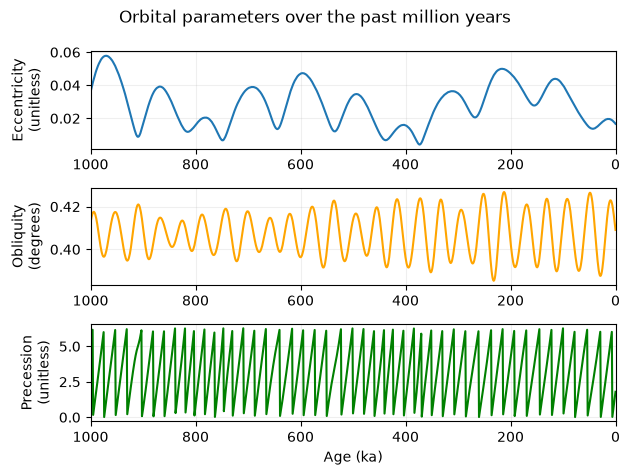

In [6]:
orbital = pd.read_csv("data/INSOLN.LA2004.BTL.100.csv")
print("Columns:", orbital.columns.tolist())
display(orbital.head())
recent_orbital = orbital.loc[orbital["Age (ka)"].between(0, 1000)].sort_values("Age (ka)")

plt.subplot(3,1,1)

plt.plot(recent_orbital["Age (ka)"], recent_orbital["Eccentricity"], label="Eccentricity")
plt.ylabel("Eccentricity\n(unitless)")
plt.grid(alpha=.2)
plt.xlim(1000,0)

plt.subplot(3,1,2)
plt.plot(recent_orbital["Age (ka)"], recent_orbital["Obliquity"], label="Obliquity", color='orange')
plt.ylabel("Obliquity\n(degrees)")
plt.grid(alpha=.2)  
plt.xlim(1000,0)


plt.subplot(3,1,3)
plt.plot(recent_orbital["Age (ka)"], recent_orbital["Precession"], label="Precession", color='green')
plt.ylabel("Precession\n(unitless)")
plt.xlabel("Age (ka)")
plt.grid(alpha=.2)
plt.xlim(1000,0)


plt.suptitle("Orbital parameters over the past million years")
plt.tight_layout()
plt.show()

<font color='red'>**Question 3:**</font> Which parameter appears to vary fastest? Which varies slowest? Are these patterns perfectly regular?

**Your answer:** ...

# Find Periods in Orbital Dataset

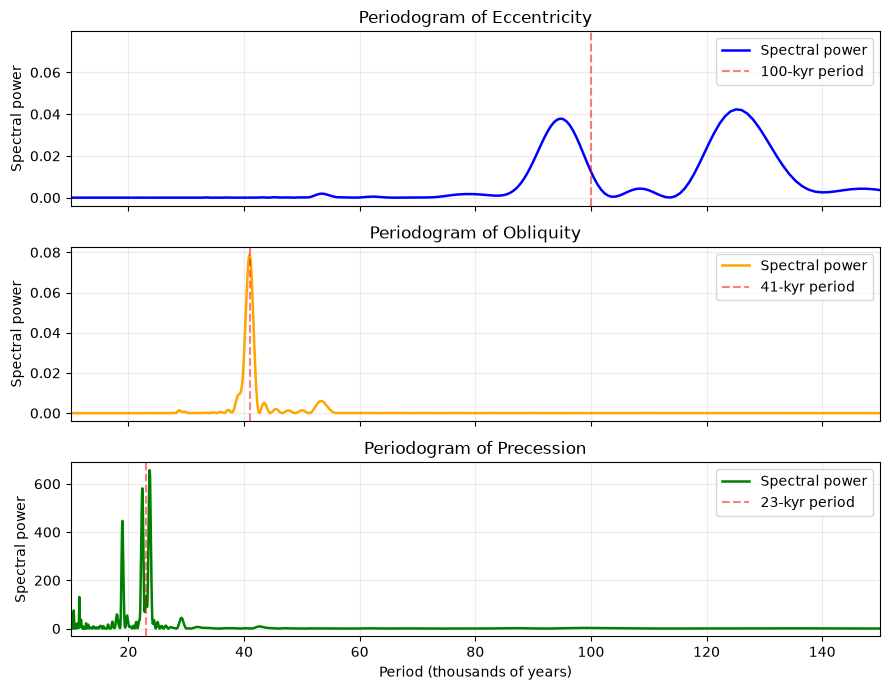

In [7]:
# 1. Compute periodograms for each orbital parameter (fs=1 assumes 1 sample per 1 ka)
freq_ecc, power_ecc = signal.periodogram(recent_orbital["Eccentricity"], fs=1, nfft=16384)
freq_obl, power_obl = signal.periodogram(recent_orbital["Obliquity"], fs=1, nfft=16384)
freq_prec, power_prec = signal.periodogram(recent_orbital["Precession"], fs=1, nfft=16384)

# 2. Remove zero frequency (infinite period) and convert frequency to period (ka)
mask = freq_ecc > 0
period_ecc = 1 / freq_ecc[mask]
period_obl = 1 / freq_obl[mask]
period_prec = 1 / freq_prec[mask]

# 3. Plot each periodogram in its own stacked panel
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)

# Top panel: Eccentricity
axes[0].plot(period_ecc, power_ecc[mask], color="blue", linewidth=1.8)
axes[0].set_ylabel("Spectral power")
axes[0].set_title("Periodogram of Eccentricity")
axes[0].grid(alpha=0.25)
axes[0].axvline(100, color="red", linestyle="--", alpha=0.5)
axes[0].legend(["Spectral power", "100-kyr period"], loc="upper right")

# Middle panel: Obliquity
axes[1].plot(period_obl, power_obl[mask], color="orange", linewidth=1.8)
axes[1].set_ylabel("Spectral power")
axes[1].set_title("Periodogram of Obliquity")
axes[1].grid(alpha=0.25)
axes[1].axvline(41, color="red", linestyle="--", alpha=0.5)
axes[1].legend(["Spectral power", "41-kyr period"], loc="upper right")

# Bottom panel: Precession
axes[2].plot(period_prec, power_prec[mask], color="green", linewidth=1.8)
axes[2].set_ylabel("Spectral power")
axes[2].set_title("Periodogram of Precession")
axes[2].grid(alpha=0.25)
axes[2].axvline(23, color="red", linestyle="--", alpha=0.5)
axes[2].legend(["Spectral power", "23-kyr period"], loc="upper right")

# 4. Set shared Period x-axis limits and label
axes[2].set_xlim(10, 150)
axes[2].set_xlabel("Period (thousands of years)")

plt.tight_layout()
plt.show()

<font color='red'>**Question 4:**</font> How does the simulated data line up with what we have said is the repeat interval for the orbital cycles?

**Your answer:** ...

In [8]:
# Filter power arrays to match the masked period arrays (periods > 0)
p_ecc = power_ecc[mask]
p_obl = power_obl[mask]
p_prec = power_prec[mask]

# Find peak indices (prominence filters out tiny side-lobes; distance prevents duplicate picks)
peaks_ecc, _ = signal.find_peaks(p_ecc, prominence=0.25 * p_ecc.max(), distance=20)
peaks_obl, _ = signal.find_peaks(p_obl, prominence=0.25 * p_obl.max(), distance=20)
peaks_prec, _ = signal.find_peaks(p_prec, prominence=0.25 * p_prec.max(), distance=20)

# Print dominant periods rounded to 1 decimal place
print("Eccentricity dominant periods (ka):", np.round(period_ecc[peaks_ecc], 1))
print("Obliquity dominant periods (ka):   ", np.round(period_obl[peaks_obl], 1))
print("Precession dominant periods (ka):  ", np.round(period_prec[peaks_prec], 1))


Eccentricity dominant periods (ka): [390.1 125.1  94.7]
Obliquity dominant periods (ka):    [41.]
Precession dominant periods (ka):   [23.7 22.4 19. ]


<font color='red'>**Question 5:**</font> Our data also showed period at `390.1 ka` for eccentricity. Why did our figure above not show that?

**Your answer:** ...

## Relating these cycles to incoming insolation

You can see a lot of cycles on different time scales. The question is how this relates to the **amount of insolation, i.e. the amount of solar energy arriving on Earth**.  In the literature, there are many attempts to convert the orbital parameters, like those in the plot above, to the amount of insolation received by the Earth's atmosphere as a function of latitude and age. You can get such estimates here: https://www.ncdc.noaa.gov/paleo-search/study/5792 associated with this paper (Huybers, P. 2006, http://www.sciencemag.org/cgi/content/full/313/5786/508).  

It is traditional to consider the amount of insolation received at 65&deg;N.  So let's take a look.

Additionally, the units in this dataset are **GJ/m<sup>2</sup>** (total energy per square meter integrated over the summer melt season) instead of **W/m<sup>2</sup>** (instantaneous flux) because we are looking at integrated summer insolation. You can think of it as accumulated insolation.

You will see values around ~ 4–6 GJ/m<sup>2</sup> instead of ~ 450–550 W/m<sup>2</sup>.

Columns: ['Age (ka)', 'Insolation (GJ/m^2)']


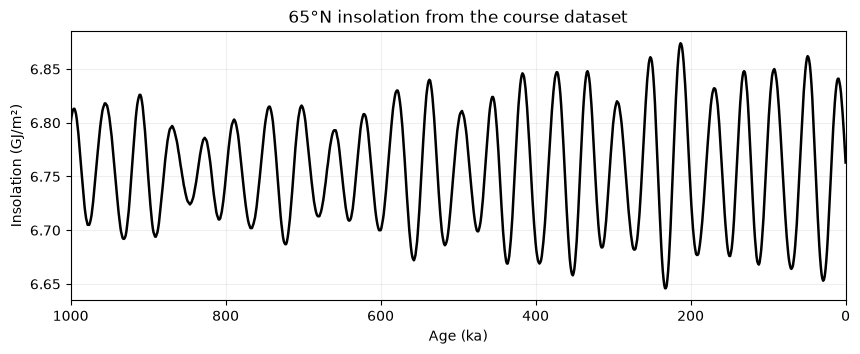

count    1001.0
mean        6.8
std         0.1
min         6.6
25%         6.7
50%         6.8
75%         6.8
max         6.9
Name: Insolation (GJ/m^2), dtype: float64


In [9]:
insolation = pd.read_csv("data/j_65north.csv")
print("Columns:", insolation.columns.tolist())
# display(insolation.head())
insol = insolation.loc[insolation["Age (ka)"].between(0, 1000)].sort_values("Age (ka)")
plt.figure(figsize=(10, 3.5))
plt.plot(insol["Age (ka)"], insol["Insolation (GJ/m^2)"], color="black", linewidth=1.8)
plt.xlim(1000, 0)
plt.xlabel("Age (ka)")
plt.ylabel("Insolation (GJ/m²)")
plt.title("65°N insolation from the course dataset")
plt.grid(alpha=.2)
plt.show()
print(insol["Insolation (GJ/m^2)"].describe().round(1))

## How big are these insolation changes?

These changes in insolation are interpretted to be important in driving glacial-interglacial cycles. How big are the changes in insolation?

The percentage difference is calculated as the difference from the mean, divided by the mean
e.g $\frac{max(a)-mean(a)}{mean(a)}$



In [10]:
# 1. Calculate mean, minimum, and maximum insolation
mean_insol = insol["Insolation (GJ/m^2)"].mean()
min_insol = insol["Insolation (GJ/m^2)"].min()
max_insol = insol["Insolation (GJ/m^2)"].max()

# 2. Calculate percentage differences from the mean
pct_diff_min = ((min_insol - mean_insol) / mean_insol) * 100
pct_diff_max = ((max_insol - mean_insol) / mean_insol) * 100

# 3. Print formatted summary
print(f"Mean insolation: {mean_insol:.2f} GJ/m²")
print(f"Min insolation:  {min_insol:.2f} GJ/m² ({pct_diff_min:.1f}% from mean)")
print(f"Max insolation:  {max_insol:.2f} GJ/m² (+{pct_diff_max:.1f}% from mean)")


Mean insolation: 6.76 GJ/m²
Min insolation:  6.65 GJ/m² (-1.6% from mean)
Max insolation:  6.87 GJ/m² (+1.7% from mean)


<font color='red'>**Question 6.**</font> Are you surprised by how small (or large) these percentage changes are?

**Your answer:...**

### What do those numbers tell us?

Even at the most extreme orbital configurations over the past million years, integrated summer solar energy at 65°N only varies by about **±1.6% to 1.7%** around its mean of **6.76 GJ/m²**. It can be thought of as a ***gentle pacemacker***

That raises two big questions for climate scientists:
1. **Which orbital cycles** (eccentricity, obliquity, or precession) actually control these subtle ±1.7% wiggles?
2. **How can such a small nudge** in summer solar energy trigger massive glacial-interglacial swings in Earth's climate?

Let's answer the first question using the exact same **periodogram** and **peak-finding** tools we used on the orbital parameters above.


## What is the dominant periodic signal in the insolation curve?

65°N Insolation dominant period(s) (ka): [41.1]


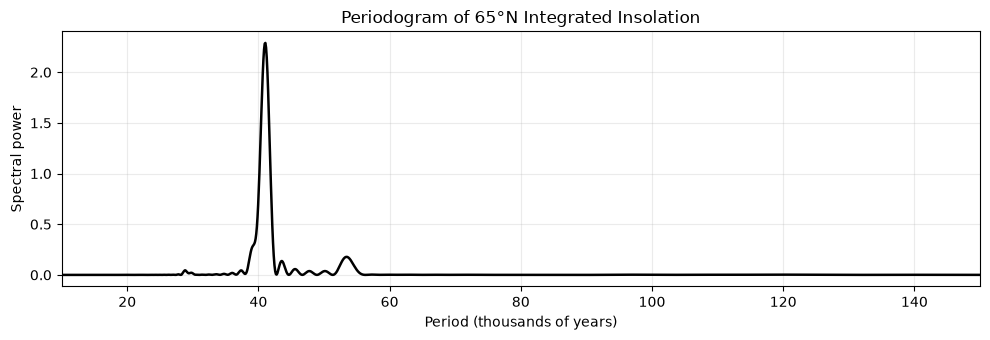

In [11]:
# 1. Compute periodogram of 65°N integrated insolation
freq_insol, power_insol = signal.periodogram(
    insol["Insolation (GJ/m^2)"], fs=1, nfft=16384
)

# 2. Convert positive frequencies to period (ka)
mask = freq_insol > 0
period_insol = 1 / freq_insol[mask]
p_insol = power_insol[mask]

# 3. Find dominant periods using the same 0.25 prominence rule
peaks_insol, _ = signal.find_peaks(
    p_insol, prominence=0.25 * p_insol.max(), distance=20
)
print("65°N Insolation dominant period(s) (ka):", np.round(period_insol[peaks_insol], 1))

# 4. Plot periodogram with detected peaks
plt.figure(figsize=(10, 3.5))
plt.plot(period_insol, p_insol, color="black", linewidth=1.8)
# plt.scatter(period_insol[peaks_insol], p_insol[peaks_insol], color="red", zorder=5)
plt.xlim(10, 150)
plt.xlabel("Period (thousands of years)")
plt.ylabel("Spectral power")
plt.title("Periodogram of 65°N Integrated Insolation")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

<font color='red'>**Question 7:**</font> Look at your periodogram and printed period(s) for 65°N insolation. Where did Precession (~23 ka) and Eccentricity (~100 ka) go?  
<font color='blue'>Hint: Kepler's second law</font> 


**Your answer:** ...

<font color='red'>**Question 8:**</font> Why might *summer* insolation near 65°N matter for whether winter snow survives to the following year? Check the dataset’s metadata to determine which seasonal insolation quantity is represented; do not assume it is an annual mean.

**Your answer:** ...

## Part 3 — What do paleoclimate records tell us? (~15 minutes)
Ice cores preserve atmospheric CO₂ information. CO₂ participates in feedbacks and also changes Earth’s radiative balance. Marine microfossils provide a much longer record: benthic **δ¹⁸O** reflects a combination of global ice volume and deep-ocean temperature, **not** temperature alone.

CO₂ columns: ['age_gas_calBP', 'co2_ppm', 'co2_1s_ppm']


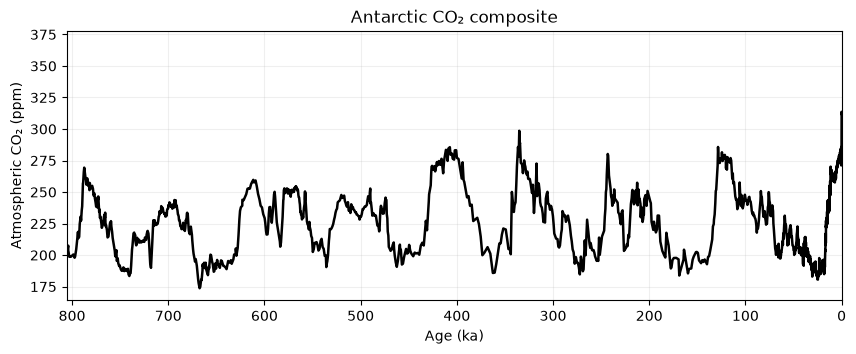

In [12]:
co2 = pd.read_csv("data/antarctica2015co2composite.txt", sep="\t", skiprows=137)
print("CO₂ columns:", co2.columns.tolist())
co2["age_ka"] = co2["age_gas_calBP"] / 1000
co2 = co2.sort_values("age_ka")
plt.figure(figsize=(10, 3.5))
plt.plot(co2["age_ka"], co2["co2_ppm"], color="black", linewidth=1.8)
plt.xlim(co2["age_ka"].max(), 0)
plt.xlabel("Age (ka)")
plt.ylabel("Atmospheric CO₂ (ppm)")
plt.title("Antarctic CO₂ composite")
plt.grid(alpha=.2)
plt.show()

<font color='red'>**Question 9:**</font> Does CO₂ stay constant through the last several glacial cycles? How many major cycles can you see?

**Your answer:** ...

Because this is *real* observational data, they are unevenly sampled in time. To analyze these data, we need to have an evenly spaced timeseries. We can use the scipy interpolation capabilities to do so using `interp1d`.

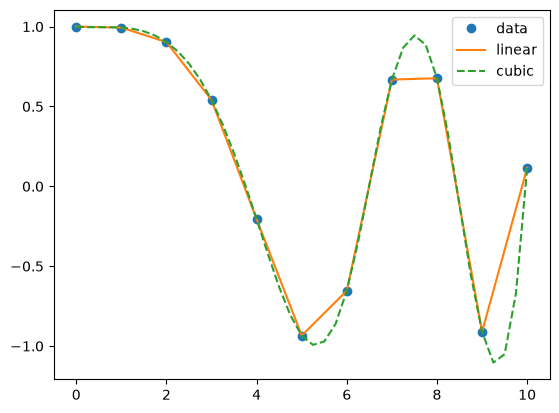

In [13]:
#Create an example function
x = np.linspace(0, 10, 11,True) #The "True" argument includes the upper limit in the series
y = np.cos(-x**2/9.0)

#Create the interpolation functions
f = interp1d(x, y, kind='linear') #linear interpolation function
f2 = interp1d(x, y, kind='cubic') #cublic spline interpolation function

#Create new x-values
xnew = np.linspace(0, 10, 41, True) #The "True" argument includes the upper limit in the series

#Create new y values with interpolation functions
ynew=f(xnew)
ynew2=f2(xnew)

#Plot original x,y and xnew,ynew
plt.plot(x, y, 'o')
plt.plot(xnew, ynew, '-')
plt.plot(xnew, ynew2, '--')
plt.legend(['data', 'linear', 'cubic'], loc='best')
plt.show()

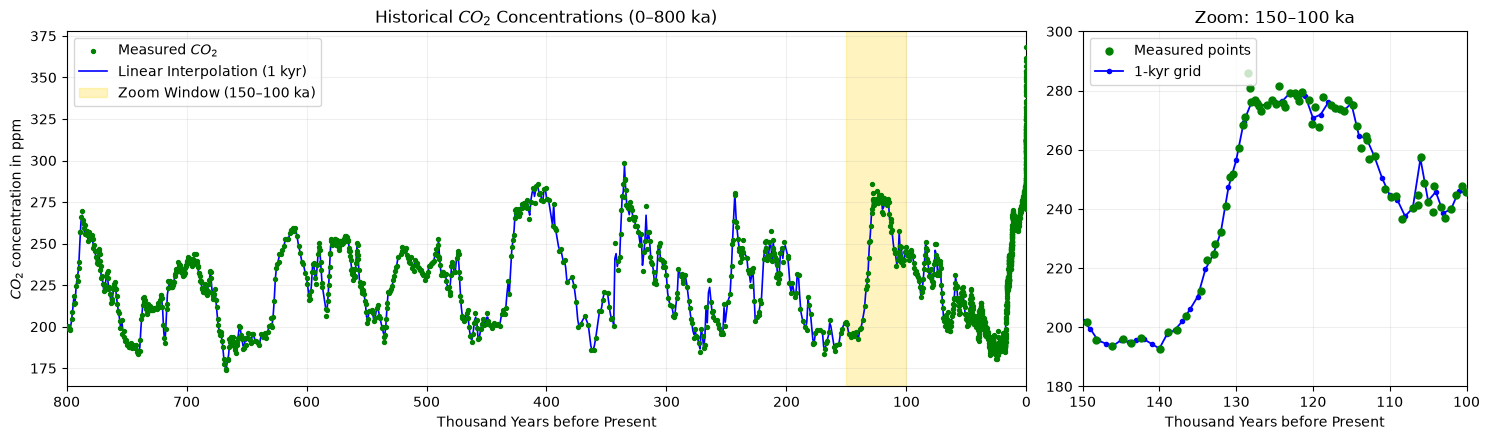

In [14]:
#Create a linear interpolation function
f = interp1d(co2['age_ka'], co2['co2_ppm'], kind='linear')

#Create a time series with 1 kyr intervals
xnew=np.linspace(0,800,801,True)

#Create new y values with interpolation functions
co2_interp =f(xnew)

# Set up side-by-side panels (wide overview on left, zoomed window on right)
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2.5, 1]}
)

# --- Left Panel: Full 800-ka Record ---
ax1.scatter(co2['age_ka'], co2['co2_ppm'], label='Measured $CO_2$', color='green', s=8, zorder=3)
ax1.plot(xnew, co2_interp, label='Linear Interpolation (1 kyr)', color='blue', linewidth=1.2)
ax1.axvspan(150, 100, color='gold', alpha=0.25, label='Zoom Window (150–100 ka)')
ax1.set_xlim(800, 0)
ax1.set_title('Historical $CO_2$ Concentrations (0–800 ka)')
ax1.set_xlabel('Thousand Years before Present')
ax1.set_ylabel('$CO_2$ concentration in ppm')
ax1.grid(alpha=0.2)
ax1.legend(loc='upper left')

# --- Right Panel: Zoomed-In View (150–100 ka) ---
ax2.scatter(co2['age_ka'], co2['co2_ppm'], color='green', s=25, zorder=3, label='Measured points')
ax2.plot(xnew, co2_interp, color='blue', marker='o', markersize=3, linewidth=1.3, label='1-kyr grid')
ax2.set_xlim(150, 100)
ax2.set_ylim(180, 300)
ax2.set_title('Zoom: 150–100 ka')
ax2.set_xlabel('Thousand Years before Present')
ax2.grid(alpha=0.2)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


# Now let's plot the CO<sub>2</sub> and the insolation data above each other.
Do we see any of the same signals?

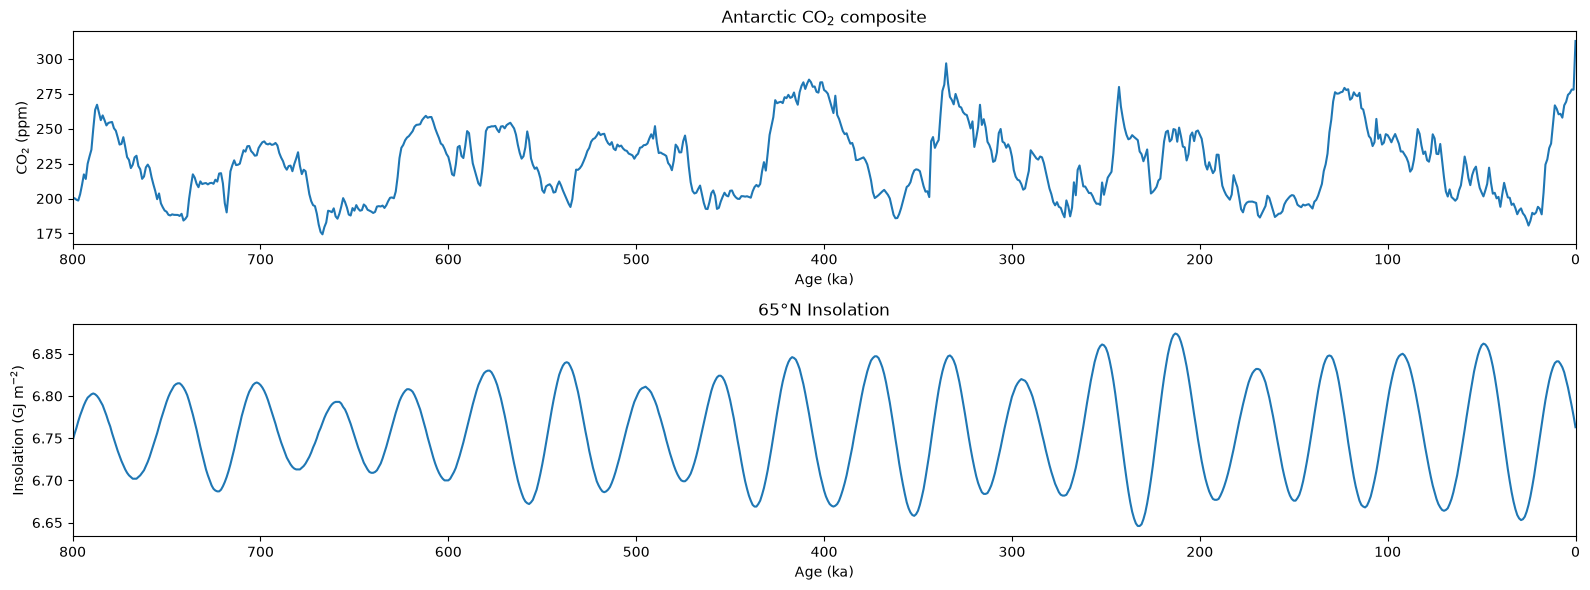

In [15]:
plt.figure(figsize=(16,6))

plt.subplot(2,1,1)
plt.title('Antarctic CO$_2$ composite')
plt.plot(xnew, co2_interp, '-')
plt.xlim(800,0)
plt.xlabel('Age (ka)')
plt.ylabel('CO$_2$ (ppm)')

plt.subplot(2,1,2)
plt.title('65°N Insolation')
plt.plot(insolation['Age (ka)'],insolation['Insolation (GJ/m^2)'])
plt.xlim(800,0)
plt.ylabel('Insolation (GJ m$^{-2}$)')
plt.xlabel('Age (ka)')

plt.tight_layout()
plt.show()

It's difficult to see any relationship when plotted as time series like this.

## What is the dominant signal in the ice sheet CO<sub>2</sub> data?

We will take the same approach above and use the `signal.periodogram()` function to calculate the power spectral density of the interpolated CO<sub>2</sub> data, `co2_interp`.


Antarctic CO₂ dominant periods (ka): [98.1 71.9 40.7]


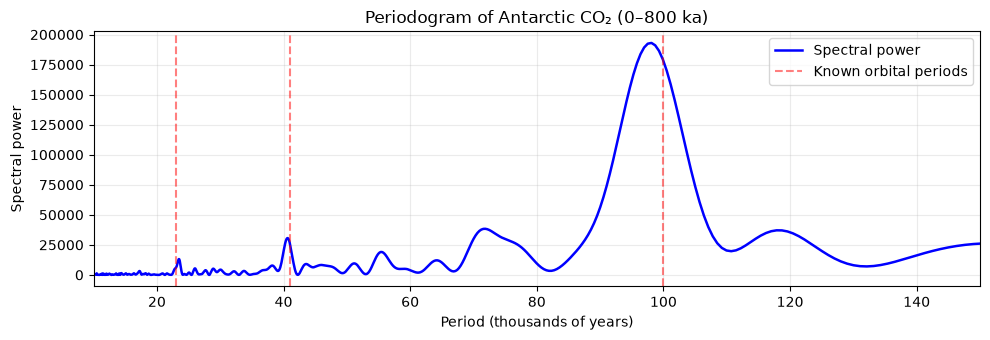

In [16]:
# 1. Compute periodogram on the evenly spaced (1-kyr) CO2 series
freq_co2, power_co2 = signal.periodogram(co2_interp, fs=1, nfft=16384)

# 2. Convert positive frequencies to period (ka)
mask = freq_co2 > 0
period_co2 = 1 / freq_co2[mask]
p_co2 = power_co2[mask]

# 3. Detect dominant periods using the same 0.25 prominence rule
peaks_co2, _ = signal.find_peaks(p_co2, prominence=0.15 * p_co2.max(), distance=20)
print("Antarctic CO₂ dominant periods (ka):", np.round(period_co2[peaks_co2], 1))

# 4. Plot periodogram
plt.figure(figsize=(10, 3.5))
plt.plot(period_co2, p_co2, color="blue", linewidth=1.8)
# plt.scatter(period_co2[peaks_co2], p_co2[peaks_co2], color="red", zorder=5)
plt.xlim(10, 150)
plt.xlabel("Period (thousands of years)")
plt.ylabel("Spectral power")
plt.title("Periodogram of Antarctic CO₂ (0–800 ka)")
plt.grid(alpha=0.25)

# vertical lines for the known orbital periods
plt.axvline(23, color="red", linestyle="--", alpha=0.5)
plt.axvline(41, color="red", linestyle="--", alpha=0.5)
plt.axvline(100, color="red", linestyle="--", alpha=0.5)

plt.legend(["Spectral power", "Known orbital periods"], loc="upper right")

plt.tight_layout()
plt.show()


<font color=red>**Question 10:**</font> Interpreting the Antarctic CO₂ Periodogram

1. **Identify the dominant cycle:** What is the strongest period in the Antarctic CO₂ record? Do you also see smaller peaks matching the **obliquity (~41 ka)** and **precession (~23 ka)** cycles?
2. **Compare forcing vs. response:** Look back at your periodogram of **65°N Integrated Insolation**. That incoming solar energy curve was dominated by **41 ka** and had **almost no power at 100 ka**. Why do you think atmospheric CO₂ (and glacial ice sheets) oscillate predominantly on a **~100-ka** rhythm even though solar forcing is strongest at **41 ka**?


## Longer timescale paleoclimate records

The ice core record is a very impressive one, but unfortunately, it only goes back ~800,000 years. While this seems like a long time, it is only 0.02% of the history of the Earth.
One way that we can go further back with a paleoclimate record is by using marine fossils such as foraminifera. Foraminifera are made of calcium carbonate: $\text{CaCO}_3$.

The oxygen isotopes ($^{16}\text{O}$ vs. $^{18}\text{O}$) in the $\text{CaCO}_3$ form a record of both temperature and ice volume. $\delta^{18}\text{O}$ is a way to express the ratio between $^{18}\text{O}$ and $^{16}\text{O}$:

$$\delta^{18}\text{O} = \left( \frac{\left(^{18}\text{O} / ^{16}\text{O}\right)_{\text{sample}}}{\left(^{18}\text{O} / ^{16}\text{O}\right)_{\text{standard}}} - 1 \right) \times 1000\text{ ‰}$$

When water is warm, the $\delta^{18}\text{O}$ incorporated into the foraminifera's $\text{CaCO}_3$ shell is lower, and when water is cold, the shell's $\delta^{18}\text{O}$ is higher. Ice volume reinforces this pattern: when there is less ice on land, the $\delta^{18}\text{O}$ of ocean water is lower, and when there is more ice (which preferentially traps lighter $^{16}\text{O}$), the $\delta^{18}\text{O}$ of ocean water is higher—further increasing the $\delta^{18}\text{O}$ of the fossil foraminifera.

Together, both effects mean that **higher benthic $\delta^{18}\text{O}$ values** are associated with a colder planet (more ice and colder deep water), and **lower benthic $\delta^{18}\text{O}$ values** are associated with a warmer planet.

A compilation of these data was published by [Lisiecki and Raymo (2005)](https://doi.org) called the LR04 stack. This is a stack of 57 records of benthic oxygen isotopic variations, several of which were independently dated using magnetostratigraphy, from all over the world's oceans.

Let's import the data and take a look at the record: 


LR04 columns: ['Age (ka)', 'd18O', 'uncertainty']


,Age (ka),d18O,uncertainty
0,0.0,3.23,0.03
1,1.0,3.23,0.04
2,2.0,3.18,0.03
3,3.0,3.29,0.03
4,4.0,3.30,0.03


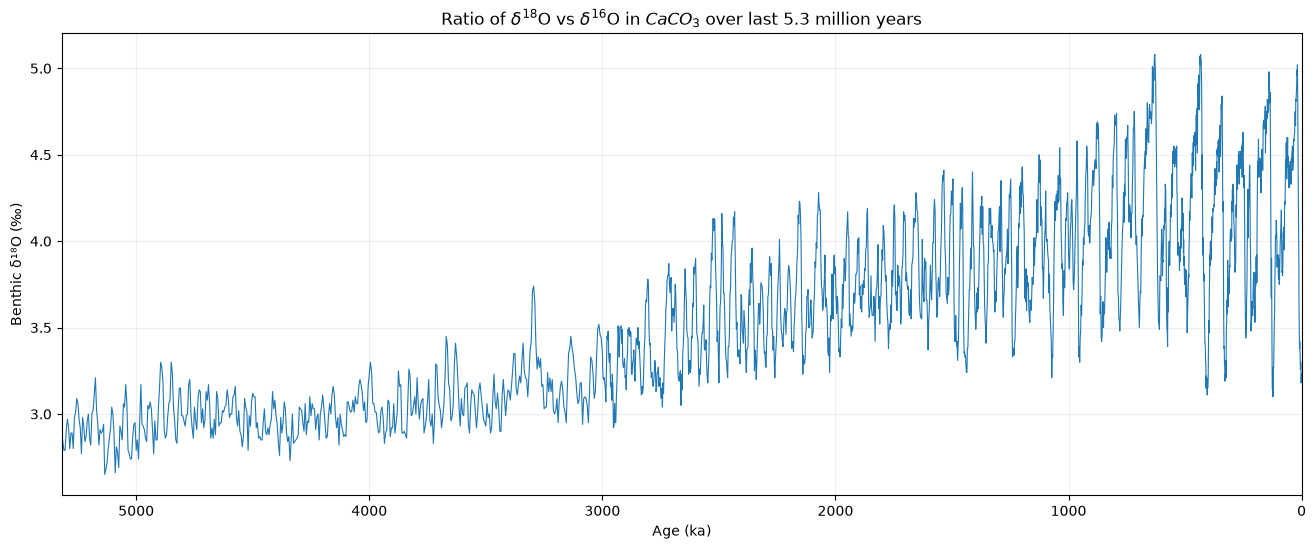

In [17]:
lr04 = pd.read_csv("data/LR04stack.csv")
print("LR04 columns:", lr04.columns.tolist())
display(lr04.head())
lr04 = lr04.sort_values("Age (ka)").dropna(subset=["Age (ka)", "d18O"])
plt.figure(figsize=(16,6))
plt.plot(lr04["Age (ka)"], lr04["d18O"], lw=.8)
plt.title('Ratio of $\\delta ^{18}$O vs $\\delta ^{16}$O in $CaCO_3$ over last 5.3 million years')
plt.xlim(lr04["Age (ka)"].max(), 0)
plt.xlabel("Age (ka)")
plt.ylabel("Benthic δ¹⁸O (‰)")
plt.grid(alpha=.2)
plt.show()

<font color='red'>**Question 11:**</font> How far back does the LR04 record extend? Why is a long record useful for investigating whether ice-age rhythms changed?

**Your answer:** ...

Let's interpolate the data and assign it to a new dataframe


In [18]:
# 1. Create the linear interpolation function (using f_d18O so the function name isn't overwritten)
f_d18O = interp1d(
    lr04['Age (ka)'], lr04['d18O'], kind='linear', fill_value='extrapolate'
)

# 2. Create a uniform 1-kyr time grid from 0 to 5,320 ka
age_uniform = np.linspace(0, 5320, 5321, True)

# 3. Evaluate the interpolation function on the uniform grid
d18O_interp = f_d18O(age_uniform)

# 4. Store in a new DataFrame
interpolated_dataframe = {'Age (ka)': age_uniform, 'd18O': d18O_interp}
lr04_d18O_interp = pd.DataFrame(data=interpolated_dataframe)
display(lr04_d18O_interp.head())


,Age (ka),d18O
0,0.0,3.23
1,1.0,3.23
2,2.0,3.18
3,3.0,3.29
4,4.0,3.30


Now let's look at the entire 5-million-year record and color-code the major climate eras:

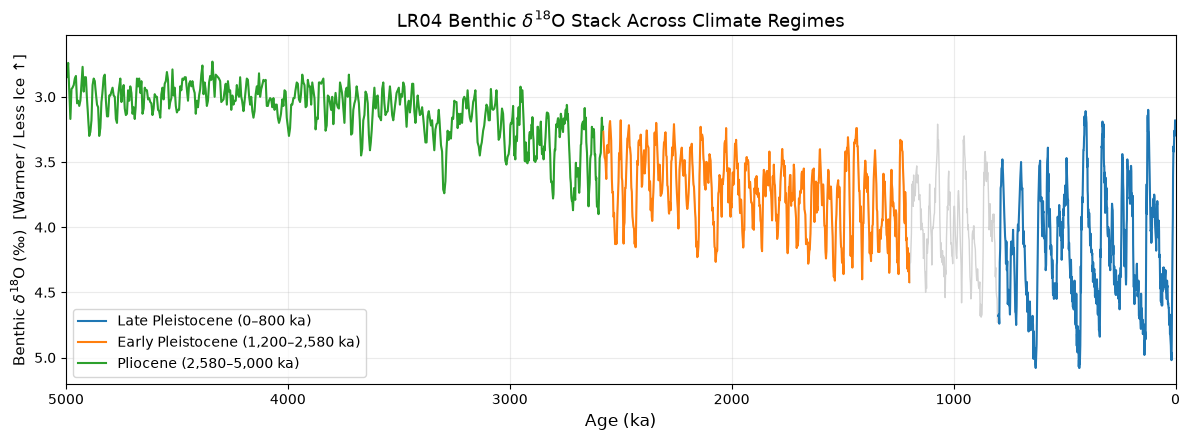

In [19]:
# 1. Split the interpolated record into three distinct climate eras
d18O_late_pleist = lr04_d18O_interp[lr04_d18O_interp['Age (ka)'] < 800]
d18O_early_pleist = lr04_d18O_interp[(lr04_d18O_interp['Age (ka)'] >= 1200) & (lr04_d18O_interp['Age (ka)'] < 2580)]
d18O_pliocene = lr04_d18O_interp[(lr04_d18O_interp['Age (ka)'] >= 2580) & (lr04_d18O_interp['Age (ka)'] <= 5000)]

# Plot the full record in light gray first so the 800–1200 ka transition stays connected
plt.figure(figsize=(12, 4.5))
plt.plot(lr04_d18O_interp['Age (ka)'], lr04_d18O_interp['d18O'], color='lightgray', linewidth=1)

# Overlay the three color-coded eras
plt.plot(d18O_late_pleist['Age (ka)'], d18O_late_pleist['d18O'], label='Late Pleistocene (0–800 ka)') # label='Late Pleistocene (0–800 ka: 100-ka world)')
plt.plot(d18O_early_pleist['Age (ka)'], d18O_early_pleist['d18O'], label='Early Pleistocene (1,200–2,580 ka)')# label='Early Pleistocene (1,200–2,580 ka: 41-ka world)')
plt.plot(d18O_pliocene['Age (ka)'], d18O_pliocene['d18O'], label='Pliocene (2,580–5,000 ka)') # label='Pliocene (2,580–5,000 ka: Warm climate)')

# Flip y-axis so warmer / less ice points UP (matching the CO2 plot)
plt.gca().invert_yaxis()
plt.xlim(5000, 0)

# plt.xlim(2580, 0)  # Uncomment this line to zoom in on the Pleistocene only

plt.title('LR04 Benthic $\\delta^{18}$O Stack Across Climate Regimes', fontsize=13)
plt.xlabel('Age (ka)', fontsize=12)
plt.ylabel('Benthic $\\delta^{18}$O (‰)  [Warmer / Less Ice ↑]', fontsize=11)
plt.legend(loc='lower left')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


<font color=red>**Question 12:**</font> Interpreting the 5-Million-Year Benthic $\delta^{18}\text{O}$ Record

Look closely at the time series above as Earth moves forward in time (from **5,000 ka on the left** to **0 ka on the right**):

1. **Long-term climate trend:** How does the average $\delta^{18}\text{O}$ value change from the Pliocene (green) through the Pleistocene (orange and blue)? What does this tell you about global temperature and ice volume over the past 5 million years?
2. **Amplitude of ice-age swings:** Compare the vertical size (peak-to-trough range) of the oscillations in the **Pliocene (green)**, **Early Pleistocene (orange)**, and **Late Pleistocene (blue)**. When do glacial-interglacial swings become largest?
3. **Rhythm and spacing:** Look at the spacing between major warm peaks in the **Early Pleistocene (orange)** compared to the **Late Pleistocene (blue)**. Which era appears to have more tightly packed, rapid oscillations, and which era has wider, longer cycles?


Early Pleistocene (1,200–2,580 ka) dominant periods (ka): [41.1]
Late Pleistocene  (0–800 ka)      dominant periods (ka): [98.1 40.8]


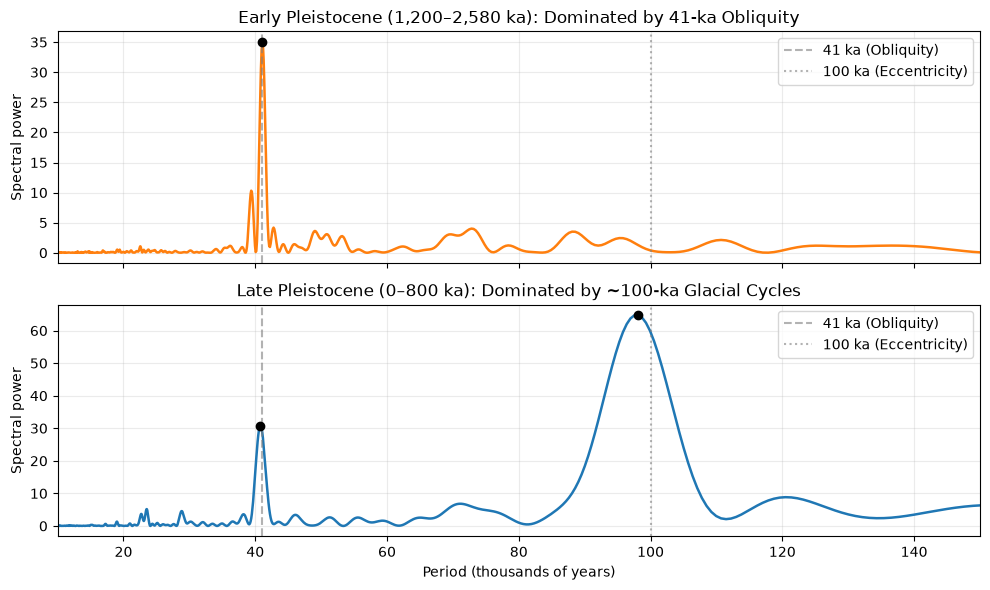

In [20]:
# 1. Compute periodograms for Early Pleistocene (orange) and Late Pleistocene (blue)
# Use detrend="linear" to remove the long-term cooling drift across each era
freq_early, power_early = signal.periodogram(
    d18O_early_pleist["d18O"], fs=1, detrend="linear", nfft=16384
)
freq_late, power_late = signal.periodogram(
    d18O_late_pleist["d18O"], fs=1, detrend="linear", nfft=16384
)

# 2. Convert positive frequencies to period (ka)
mask_early = freq_early > 0
period_early = 1 / freq_early[mask_early]
p_early = power_early[mask_early]

mask_late = freq_late > 0
period_late = 1 / freq_late[mask_late]
p_late = power_late[mask_late]

# 3. Detect dominant periods using the same 0.25 prominence rule
peaks_early, _ = signal.find_peaks(p_early, prominence=0.25 * p_early.max(), distance=20)
peaks_late, _ = signal.find_peaks(p_late, prominence=0.25 * p_late.max(), distance=20)

print("Early Pleistocene (1,200–2,580 ka) dominant periods (ka):", np.round(period_early[peaks_early], 1))
print("Late Pleistocene  (0–800 ka)      dominant periods (ka):", np.round(period_late[peaks_late], 1))

# 4. Plot two-panel comparison (matching the orange & blue era colors above)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top Panel: Early Pleistocene (41-ka world)
ax1.plot(period_early, p_early, color="tab:orange", linewidth=1.8)
ax1.scatter(period_early[peaks_early], p_early[peaks_early], color="black", zorder=5)
ax1.axvline(41, color="gray", linestyle="--", alpha=0.6, label="41 ka (Obliquity)")
ax1.axvline(100, color="gray", linestyle=":", alpha=0.6, label="100 ka (Eccentricity)")
ax1.set_ylabel("Spectral power")
ax1.set_title("Early Pleistocene (1,200–2,580 ka): Dominated by 41-ka Obliquity")
ax1.legend(loc="upper right")
ax1.grid(alpha=0.25)

# Bottom Panel: Late Pleistocene (100-ka world)
ax2.plot(period_late, p_late, color="tab:blue", linewidth=1.8)
ax2.scatter(period_late[peaks_late], p_late[peaks_late], color="black", zorder=5)
ax2.axvline(41, color="gray", linestyle="--", alpha=0.6, label="41 ka (Obliquity)")
ax2.axvline(100, color="gray", linestyle=":", alpha=0.6, label="100 ka (Eccentricity)")
ax2.set_ylabel("Spectral power")
ax2.set_xlabel("Period (thousands of years)")
ax2.set_title("Late Pleistocene (0–800 ka): Dominated by ~100-ka Glacial Cycles")
ax2.set_xlim(10, 150)
ax2.legend(loc="upper right")
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## The Mid-Pleistocene Transition (MPT)

Look at the two periodograms you just generated:
* During the **Early Pleistocene (1,200–2,580 ka)**, Earth's climate oscillated strongly at **41 ka**—matching the **obliquity** cycle we saw in 65°N integrated summer insolation.
* During the **Late Pleistocene (0–800 ka)**, the dominant climate rhythm shifted dramatically to **~100 ka**, even though Earth's orbital cycles did not change!

This major reorganization of Earth's glacial cycles—which occurred roughly between **1,250 and 700 ka** (the gray transition segment in your time-series plot)—is known as the **Mid-Pleistocene Transition (MPT)**.

### Why did Earth switch from a 41-ka world to a 100-ka world?

We don't exactly know, but leading theories believe that because incoming solar radiation (orbital forcing) behaved the exact same way before and after the MPT, the shift had to come from **internal changes within the Earth system** as the planet gradually cooled:

1. **Larger, thicker ice sheets ("skipping beats"):** As long-term global cooling allowed Northern Hemisphere ice sheets to grow thicker and expand farther south, they became too massive to melt completely during every 41-ka obliquity warming peak. Instead, ice sheets began surviving one or two obliquity cycles—building up over **80–120 ka** (two to three obliquity beats) before collapsing rapidly.
2. **Bedrock erosion (the "regolith hypothesis"):** Early Pleistocene ice sheets sat on a loose, slippery layer of soil and sediment (regolith), which kept them thin and easy to melt every 41 ka. Over hundreds of thousands of years, repeated glaciations scraped away that loose soil down to hard crystalline bedrock, allowing much thicker, steeper ice sheets to form.
3. **Stronger ocean carbon feedbacks:** Cooler deep oceans, expanded Southern Ocean sea ice, and shifts in ocean circulation trapped more $\text{CO}_2$ in the abyssal ocean during glacial periods, amplifying global cooling and locking the climate into deeper, longer ice ages.

<font color=red>**Question 13:**</font> Putting It All Together

1. **Forcing vs. Response:** Based on everything you analyzed in Parts 1–3, why can't we explain the last 800,000 years of ice ages using incoming solar radiation (`j_65north.csv`) alone?
2. **Signal Processing Takeaway:** How did periodograms allow us to uncover the Mid-Pleistocene Transition in the LR04 $\delta^{18}\text{O}$ record, even though the raw time series looks noisy?


## Part 4 — Putting the evidence together (~10 minutes)
**Discuss with a partner, then answer in your own words:**

1. What changed about glacial–interglacial variability across the MPT? Cite evidence from at least two intervals.
2. Which orbital timescale is closest to the dominant rhythm of the older cycles? Which is closest to the later cycles?
3. Why is it **not** enough to say “eccentricity caused the 100-kyr ice ages”? Consider ice sheets, CO₂, ocean circulation, and other feedbacks.
4. What is one limitation of using a periodogram to explain past climate?

**Your answers:** ...

### Summary

- $\delta^{18}\text{O}$ records **palaeotemperature**
- CO<sub>2</sub> data shows the **response to climate forcings** (up until the present day when things have changed)
- Solar insolation (controlled by the orbital paramters) **influences the amount of energy arriving on Earth** in the northern hemisphere
- **Both the $\delta^{18}\text{O}$ and CO<sub>2</sub> have the same periodicities as the orbital parameters (Milankovitch cycles), showing that palaeoclimate is controlled by the Earth's orbit, and enhanced by feedbacks such as CO<sub>2</sub> release.**
- Milankovitch cycles can be observed in the geological record
<img src="./figures/Milankovitch-cycles-in-an-outcrop-of-Permian-marine-carbonates.png" width = 1200>
Visual identification of Milankovitch cycles in an outcrop of Permian marine carbonates from the Dalong Formation, China (modified from Wu et al. 2013). Note the groups of layers identified as a product of precession forming cycles of 100 kyr (short eccentricity) regrouped in cycles of 405 kyr (long eccentricity). Source: modified from Wu et al. (2013).

## Exit ticket
Complete these sentences before you leave:

- One thing I learned about **Python** is ...
- One thing I learned about **glacial cycles** is ...
- One question I still have is ...

**Submission:** 

**Data and attribution:** 